In [7]:
# upload dataset
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
dataset_path = '/content/drive/MyDrive/Colab/augmented.csv'

# Load the dataset
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Please ensure it exists in your Google Drive.")
    df = None

if df is not None:
    # Display the first 5 rows of the DataFrame
    print("\nFirst 5 rows of the dataset:")
    display(df.head())
    # Display basic information about the DataFrame
    print("\nDataFrame Info:")
    df.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.

First 5 rows of the dataset:


,user,gender,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,...,pitch2,yaw2,mag3,roll3,pitch3,yaw3,mag4,roll4,pitch4,yaw4
0,debora,Woman,46,1.62,75,28.6,-3,92,-63,-23,...,41.308515,141.952957,138.942434,131.496468,-2.062298,87.247515,233.918789,-144.981829,39.884957,-145.523912
1,debora,Woman,46,1.62,75,28.6,-3,94,-64,-21,...,39.521196,139.398705,138.246157,130.872408,5.812229,97.666804,232.469353,-144.350344,39.862300,-145.085476
2,debora,Woman,46,1.62,75,28.6,-1,97,-61,-12,...,25.641006,120.963757,138.148471,130.872408,5.399617,97.125016,233.137299,-144.162347,40.367439,-145.443194
3,debora,Woman,46,1.62,75,28.6,-2,96,-57,-15,...,29.603745,125.537678,137.499091,130.555894,5.425194,97.125016,232.770273,-144.044667,41.094312,-146.051457
4,debora,Woman,46,1.62,75,28.6,-1,96,-61,-13,...,27.474432,123.023868,137.499091,130.555894,5.425194,97.125016,233.824721,-143.972627,40.869343,-145.794542



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165633 entries, 0 to 165632
Data columns (total 35 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user                165633 non-null  object 
 1   gender              165633 non-null  object 
 2   age                 165633 non-null  int64  
 3   how_tall_in_meters  165633 non-null  float64
 4   weight              165633 non-null  int64  
 5   body_mass_index     165633 non-null  float64
 6   x1                  165633 non-null  int64  
 7   y1                  165633 non-null  int64  
 8   z1                  165633 non-null  int64  
 9   x2                  165633 non-null  int64  
 10  y2                  165633 non-null  int64  
 11  z2                  165633 non-null  int64  
 12  x3                  165633 non-null  int64  
 13  y3                  165633 non-null  int64  
 14  z3                  165633 non-null  int64  
 15  x4               

Numeric columns present: ['age', 'how_tall_in_meters', 'weight', 'body_mass_index', 'x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4', 'mag1', 'roll1', 'pitch1', 'yaw1', 'mag2', 'roll2', 'pitch2', 'yaw2', 'mag3', 'roll3', 'pitch3', 'yaw3', 'mag4', 'roll4', 'pitch4', 'yaw4']


,count,mean,std,min,25%,50%,75%,max
age,165633.0,38.265146,13.184091,28.000000,28.000000,31.000000,46.000000,75.000000
how_tall_in_meters,165633.0,1.639712,0.052820,1.580000,1.580000,1.620000,1.710000,1.710000
weight,165633.0,70.819408,11.296527,55.000000,55.000000,75.000000,83.000000,83.000000
body_mass_index,165633.0,26.188522,2.995777,22.000000,22.000000,28.400000,28.600000,28.600000
x1,165633.0,-6.649327,11.616238,-306.000000,-12.000000,-6.000000,0.000000,509.000000
y1,165633.0,88.293667,23.895829,-271.000000,78.000000,94.000000,101.000000,533.000000
z1,165633.0,-93.164611,39.409423,-603.000000,-120.000000,-98.000000,-64.000000,411.000000
x2,165633.0,-87.827504,169.435194,-494.000000,-35.000000,-9.000000,4.000000,473.000000
y2,165633.0,-52.065047,205.159763,-517.000000,-29.000000,27.000000,86.000000,295.000000
z2,165633.0,-175.055200,192.816615,-617.000000,-141.000000,-118.000000,-29.000000,122.000000


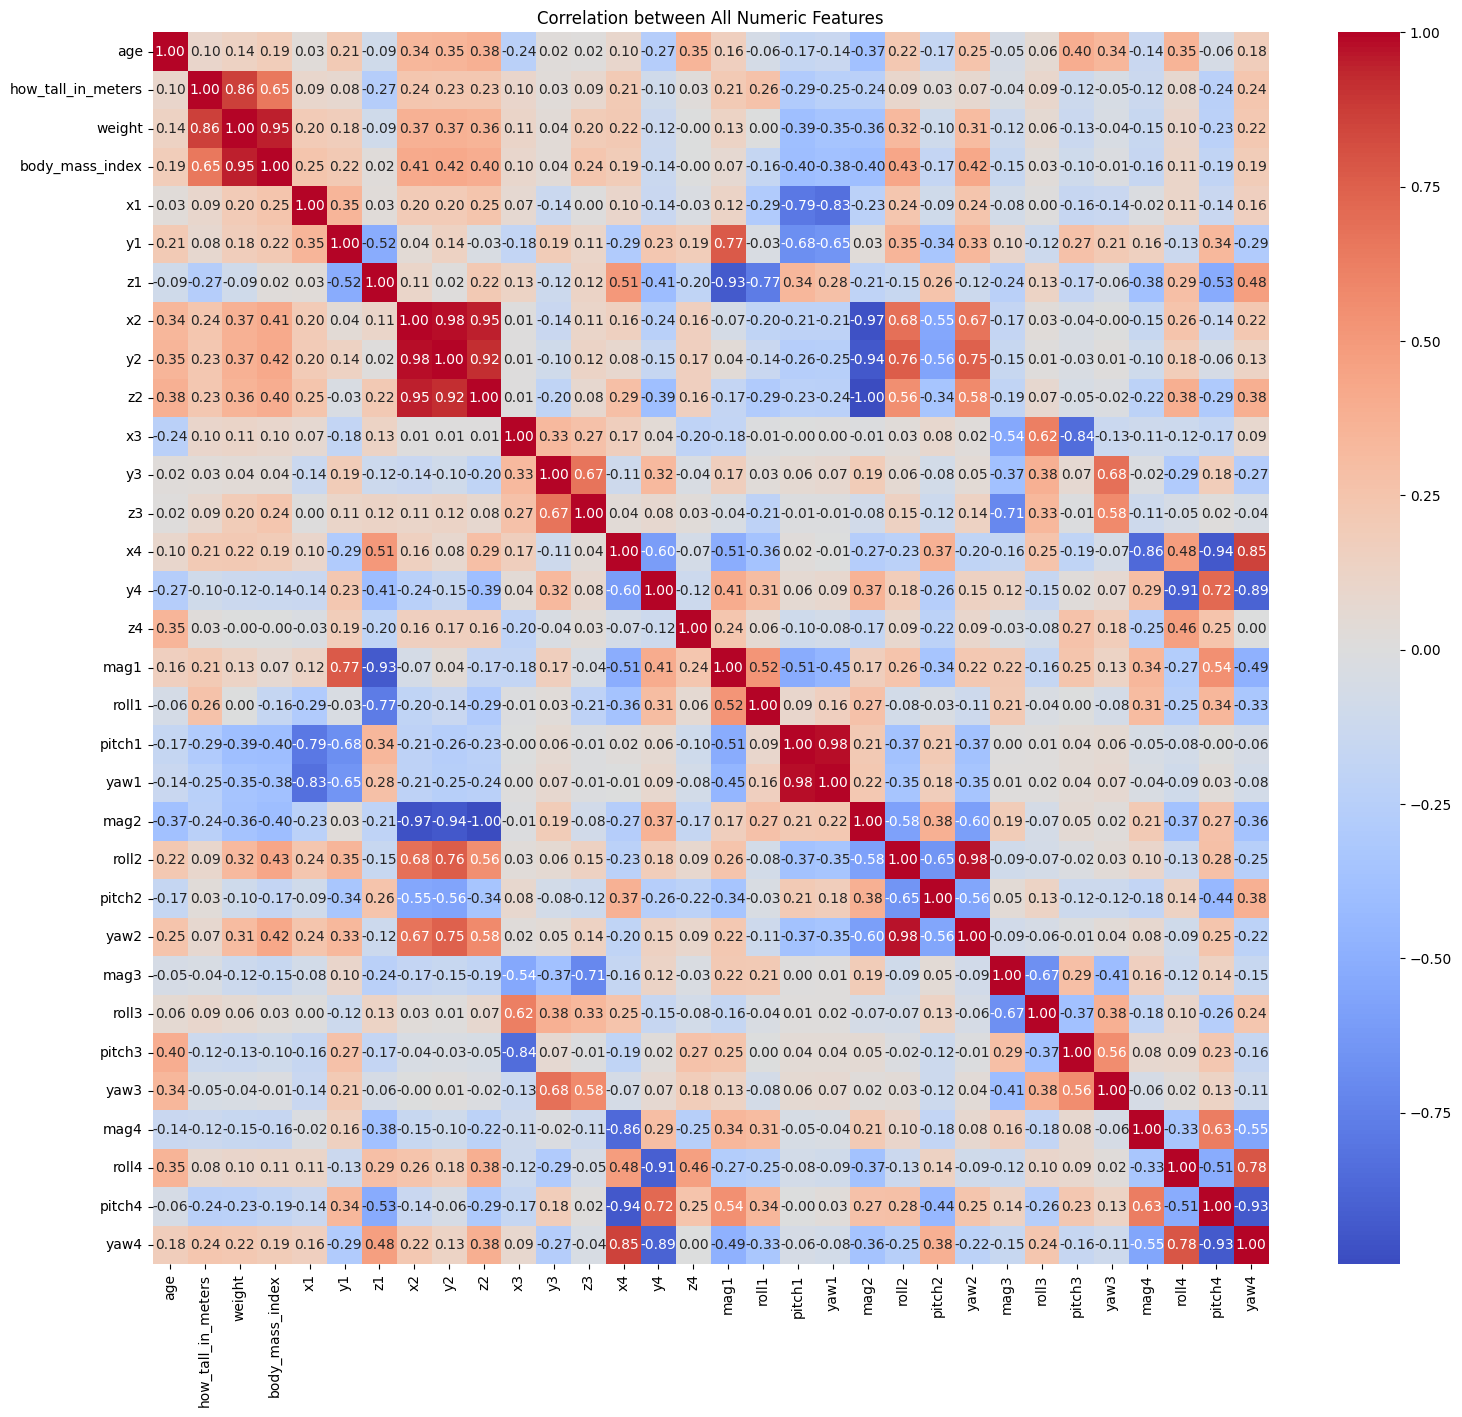

In [9]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display

# Select all numeric columns for correlation analysis
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print('Numeric columns present:', numeric_cols)

if len(numeric_cols) == 0:
    print('No numeric columns found in the dataframe. Skipping correlation analysis.')
else:
    # Summary statistics for numeric columns
    display(df[numeric_cols].describe().T)

    # Correlation heatmap between all numeric features
    corr = df[numeric_cols].corr()
    plt.figure(figsize=(18, 16)) # Increased figure size for better readability with more features
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
    plt.title('Correlation between All Numeric Features')
    plt.show()

In [12]:
highly_correlated_pairs = []

# Iterate through the correlation matrix
# We only need to check the upper triangle to avoid duplicate pairs and self-correlation
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) >= 0.9: # Changed threshold to 0.9
            col1 = corr.columns[i]
            col2 = corr.columns[j]
            correlation_value = corr.iloc[i, j]
            highly_correlated_pairs.append((col1, col2, correlation_value))

if highly_correlated_pairs:
    print("Coppie di feature con correlazione maggiore o uguale a 0.90:")
    for col1, col2, correlation_value in highly_correlated_pairs:
        print(f"- {col1} e {col2}: {correlation_value:.2f}")
else:
    print("Nessuna coppia di feature trovata con correlazione maggiore o uguale a 0.90.")

Coppie di feature con correlazione maggiore o uguale a 0.90:
- weight e body_mass_index: 0.95
- z1 e mag1: -0.93
- x2 e y2: 0.98
- x2 e z2: 0.95
- x2 e mag2: -0.97
- y2 e z2: 0.92
- y2 e mag2: -0.94
- z2 e mag2: -1.00
- x4 e pitch4: -0.94
- y4 e roll4: -0.91
- pitch1 e yaw1: 0.98
- roll2 e yaw2: 0.98
- pitch4 e yaw4: -0.93
